11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)
CNN input shape: (60000, 28, 28, 1)


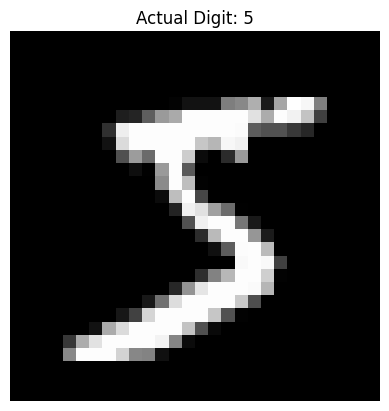

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 43s 49ms/step - accuracy: 0.9372 - loss: 0.2044 - val_accuracy: 0.9858 - val_loss: 0.0490
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 81s 48ms/step - accuracy: 0.9802 - loss: 0.0649 - val_accuracy: 0.9873 - val_loss: 0.0436
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9852 - loss: 0.0480 - val_accuracy: 0.9882 - val_loss: 0.0436
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9893 - loss: 0.0361 - val_accuracy: 0.9898 - val_loss: 0.0352
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9902 - loss: 0.0302 - val_accuracy: 0.9915 - val_loss: 0.0342



Test Loss: 0.029804110527038574
Test Accuracy: 0.9901000261306763
Predicted Digit: 7
Actual Digit: 7
Confidence: 100.0 %


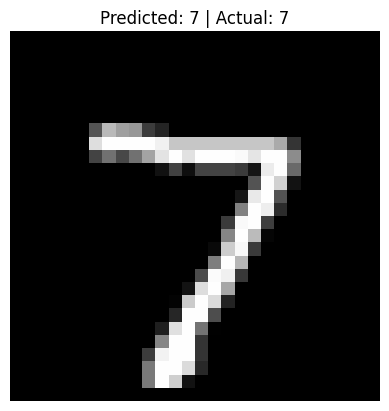

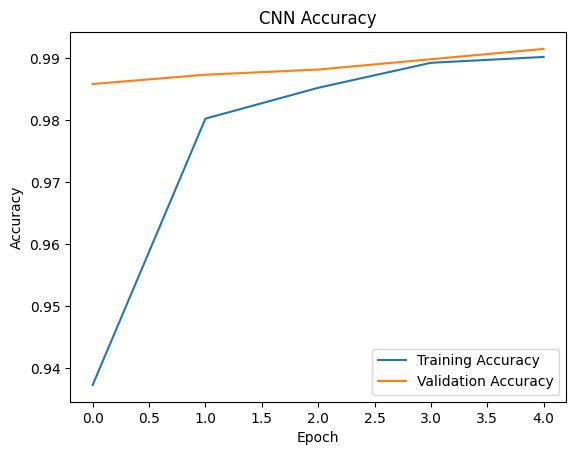

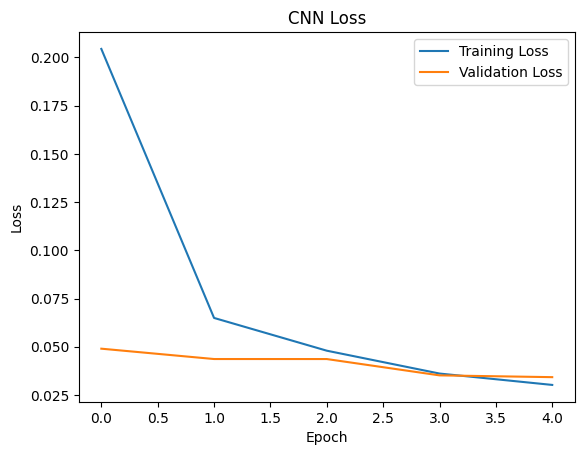

In [10]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers

# 1. Load the dataset
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

# 2. Normalize pixel values from 0-255 to 0-1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# 3. Add the channel dimension (grayscale = 1 channel)
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("CNN input shape:", X_train.shape)

# 4. Display a sample image
plt.imshow(X_train[0].squeeze(), cmap="gray")
plt.title(f"Actual Digit: {y_train[0]}")
plt.axis("off")
plt.show()

# 5. Build the CNN model
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Extract basic image features
    layers.Conv2D(32, kernel_size=(3, 3),
                  activation="relu"),

    # Reduce image dimensions
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Extract more complex features
    layers.Conv2D(64, kernel_size=(3, 3),
                  activation="relu"),

    layers.MaxPooling2D(pool_size=(2, 2)),

    # Convert feature maps into a vector
    layers.Flatten(),

    # Learn from extracted features
    layers.Dense(128, activation="relu"),

    # Reduce overfitting
    layers.Dropout(0.3),

    # 10 possible digit classes
    layers.Dense(10, activation="softmax")
])

# 6. Display model architecture
model.summary()

# 7. Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 8. Train the model
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

# 9. Evaluate on unseen test images
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 10. Predict one test image
index = 0

image = X_test[index:index + 1]
probabilities = model.predict(image, verbose=0)

predicted_digit = np.argmax(probabilities[0])
actual_digit = y_test[index]

print("Predicted Digit:", predicted_digit)
print("Actual Digit:", actual_digit)
print("Confidence:", round(float(np.max(probabilities)) * 100, 2), "%")

plt.imshow(X_test[index].squeeze(), cmap="gray")
plt.title(f"Predicted: {predicted_digit} | Actual: {actual_digit}")
plt.axis("off")
plt.show()

# 11. Plot training and validation accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()
plt.show()

# 12. Plot training and validation loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()
plt.show()
